Version 2: trained the heads of DINOv2 and DINO v3, frozen heads for SD and Swin

In [1]:
import numpy as np 
import os, json, math, torch, random, copy, time
from PIL import Image
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import torchvision.models as models
import torch.optim as optim
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import GroupKFold
from transformers import AutoModel
from diffusers import StableDiffusionPipeline
from torchvision.models import swin_t, Swin_T_Weights
from torchvision.models.feature_extraction import create_feature_extractor

/Users/valentinaemili/miniconda3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1110 11:43:36.647000 13172 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [63]:
root = '.'
out = '.'
device = 'mps'

models = ['dinov2', 'dinov3', 'sd', 'swin']   
models_to_train = ['dinov2', 'dinov3']                    
epochs, learning_rate, accum = 12, 5e-4, 4                 # ACCUM = pairs per optimizer step
map_size, window_size = 96, 5                                  
fold, n_folds = 0, 5
random.seed(0); np.random.seed(0); torch.manual_seed(0)

# Data

one sample = one pair with all its queries

In [64]:
def load_pairs(csv_file, has_targets):
    df = pd.read_csv(f'{root}/{csv_file}')
    pairs = []
    for _, g in df.groupby('pair_id', sort=False):
        queries = []
        for r in g.itertuples():
            q = dict(id=str(r.id), xy=(r.source_x, r.source_y))
            if has_targets:
                q['targets'] = json.loads(r.target_points)    # accepted target points
                q['L'] = r.scale                              # PCK tolerance = 0.1 * L
            queries.append(q)
        pairs.append(dict(source_image=g.source_image.iloc[0], target_image=g.target_image.iloc[0], queries=queries))
    return pairs

train_pairs = load_pairs('train.csv', True)
test_pairs = load_pairs('test.csv', False)

images = sorted({i for p in train_pairs for i in (p['source_image'], p['target_image'])})
index = {name: k for k, name in enumerate(images)}
rows = [index[p['source_image']] for p in train_pairs]
cols = [index[p['target_image']] for p in train_pairs]
graph = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(images), len(images)))
_, component = connected_components(graph, directed=False)
groups = [component[index[p['source_image']]] for p in train_pairs]

train, val = list(GroupKFold(n_folds).split(np.zeros(len(train_pairs)), groups=groups))[fold]
fit_pairs = [train_pairs[i] for i in train]
val_pairs = [train_pairs[i] for i in val]
print(len(fit_pairs), 'fit pairs,', len(val_pairs), 'val pairs,', len(test_pairs), 'test pairs')

_cache = {}
def load(rel):
    if rel not in _cache:
        _cache[rel] = Image.open(f'{root}/{rel}').convert('RGB')
    return _cache[rel]

313 fit pairs, 79 val pairs, 98 test pairs


In [4]:
!pip install -U transformers
from huggingface_hub import login
login()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 89.3 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2


# Backbones

DINOv2, DINOv3, SD and Swin are frozen.

Vision Transformers: It cuts the image into square patches (14×14 px for DINOv2, 16×16 for DINOv3) and turns each patch into a vector. Layers of attention then let every patch look at all the others. The input sequence is [CLS token, (register tokens), patch tokens]. The CLS token summarizes the whole image, and DINOv3 adds 4 register tokens as scratch space. You only want the patch tokens.

DINOv2 returns 37x37 patch tokens, while DINOv3 returns 32x32 patch tokens.

Stable Diffusion 2.1 generates images from text and has three parts:
* VAE: compresses an image into a small “latent” and can decompress it again
* UNet: the denoiser
* text encoder: turns a prompt into numbers that steer the UNet

In [65]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def to_tensor(image, size, flip):
    img = image.resize((size, size), Image.BICUBIC)
    if flip:
        img = img.transpose(Image.FLIP_LEFT_RIGHT) # horizontal flip
    # PIL image to tensor
    tensor_image = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float() / 255 # channels x height x width
    return ((tensor_image - mean) / std)[None].to(device) # 1 x channels x height x width

class Dino(nn.Module):
    # size = std image res; tta = img res used to test-time augmentation
    def __init__(self, huggingface_id, size, tta):
        super().__init__()
        # load pre-trained model and freeze params
        self.model = AutoModel.from_pretrained(huggingface_id).eval().to(device).requires_grad_(False)
        depth = self.model.config.num_hidden_layers
        # three layers
        self.layers = [round(0.67 * depth), round(0.83 * depth), depth]
        self.patch = self.model.config.patch_size
        self.dims = [self.model.config.hidden_size] * 3
        self.size, self.tta = size, tta
    @torch.no_grad()
    def forward(self, x):
        # n. patches per dim
        h, w = x.shape[2] // self.patch, x.shape[3] // self.patch
        # returns the outputs of all transformer layers
        hidden_states = self.model(pixel_values=x, output_hidden_states=True).hidden_states
        # hidden_states[layer] has shape 1 x tokens x 1024; select the last h*w tokens (drop CLS/register tokens)
        return [hidden_states[layer][:, -h * w:].transpose(1, 2).reshape(1, -1, h, w).float() for layer in self.layers] # each layer of shape 1 x 1024 x h x w
        
class SD(nn.Module):
    # DIFT-style: noise the VAE latent, run the UNet, take the output of one up-block
    def __init__(self, huggingface_id='sd2-community/stable-diffusion-2-1', timestep=261):
        super().__init__()
        pipeline = StableDiffusionPipeline.from_pretrained(huggingface_id, dtype=torch.float16, safety_checker=None).to(device)
        # VAE: converts images into latent representations
        # UNet: processes noisy latent representations
        self.vae, self.unet, self.timestep = pipeline.vae, pipeline.unet, timestep
        # converts text into tokens, corresponding to an empty text prompt (goal: extract image feature without conditioning on text prompt)
        ids = pipeline.tokenizer('', padding='max_length', max_length=77, return_tensors='pt').input_ids.to(device)
        with torch.no_grad():
            # converts tokens into text embeddings
            self.embeddings = pipeline.text_encoder(ids)[0]
        self.a = float(pipeline.scheduler.alphas_cumprod[timestep])
        self.dims, self.size, self.tta = [1280], 768, (768,)
    @torch.no_grad()
    def forward(self, x):
        # map images in [-1, 1]
        img = ((x * std.to(device) + mean.to(device)) * 2 - 1).half()
        # 2 copies which will get two different noises
        z = (self.vae.encode(img).latent_dist.mean * self.vae.config.scaling_factor).repeat(2, 1, 1, 1)
        noise = torch.randn(z.shape, generator=torch.Generator(device).manual_seed(0), device=device, dtype=z.dtype)
        zt = self.a ** 0.5 * z + (1 - self.a) ** 0.5 * noise
        out = {}
        hook = self.unet.up_blocks[1].register_forward_hook(lambda m, i, o: out.update(f=o[0] if isinstance(o, tuple) else o))
        self.unet(zt, self.timestep, encoder_hidden_states=self.embeddings.expand(len(zt), -1, -1))
        hook.remove()
        return [out['f'].float().mean(0, keepdim=True)]

class Swin(nn.Module):
    def __init__(self):
        super().__init__()
        m = swin_t(weights=Swin_T_Weights.DEFAULT).eval()
        self.feature_extractor = create_feature_extractor(m, {'features.3': 'a', 'features.5': 'b', 'features.7': 'c'}).to(device).requires_grad_(False)
        self.dims, self.size, self.tta = [192, 384, 768], 512, (448, 512, 576)
    @torch.no_grad()
    def forward(self, x):
        f = [v.permute(0, 3, 1, 2).float() for v in self.feature_extractor(x).values()]
        return [f[0]] + [F.interpolate(v, size=f[0].shape[-2:], mode='bilinear') for v in f[1:]]

build = {
    'dinov2': lambda: Dino('facebook/dinov2-large', 518, (448, 518, 602)),
    'dinov3': lambda: Dino('facebook/dinov3-vitl16-pretrain-lvd1689m', 512, (448, 512, 608)),   # gated: accept the licence on the HF hub
    'sd': lambda: SD(),
    'swin': lambda: Swin(),
}
backbones = {n: build[n]() for n in models}

Fetching 13 files:  31%|███       | 4/13 [03:27<07:46, 51.83s/it]


TypeError: process() takes no keyword arguments

# Head

In [ ]:
class Head(nn.Module):
    def __init__(self, dims, rank=64):
        super().__init__()
        self.down = nn.ModuleList([nn.Conv2d(c, rank, 1, bias=False) for c in dims])
        self.up = nn.ModuleList([nn.Conv2d(rank, c, 1) for c in dims])
        for u in self.up:
            nn.init.zeros_(u.weight); nn.init.zeros_(u.bias)
        self.layer_w = nn.Parameter(torch.zeros(len(dims)))
        self.log_scale = nn.Parameter(torch.tensor(math.log(30.0)))

    def adapt(self, i, f):
        f = F.normalize(f, dim=1)
        return F.normalize(f + self.up[i](self.down[i](f)), dim=1)

    def forward(self, fs, ft, q):
        # fs, ft: lists of [1,C,h,w] source / target features; q: [Q,2] query points in [0,1] source coordinates
        w = self.layer_w.softmax(0)
        sim = 0
        for i, (a, b) in enumerate(zip(fs, ft)):
            a, b = self.adapt(i, a), self.adapt(i, b)
            qf = F.grid_sample(a, (q * 2 - 1).view(1, -1, 1, 2), padding_mode='border', align_corners=False)[0, :, :, 0].t()   # [Q,C]
            sim = sim + w[i] * torch.einsum('qc,chw->qhw', F.normalize(qf, dim=1), b[0])
        return self.log_scale.exp() * sim          # logits [Q,h,w]

heads = {n: Head(backbones[n].dims).to(device) for n in models}

NameError: name 'backbones' is not defined

# Prediction and metric

`probs` gives one backbone's probability map for every query of a pair, averaged over its test-time views on a common GxG grid. 
`fuse` multiplies the maps: it computes the weighted sum of log-probabilites
`decode` takes a soft-argmax in a small window around the peak

In [56]:
def unit_points(p, img, flip):
    W, H = img.size
    u = np.array([q['xy'][0] / W for q in p['queries']])
    v = np.array([q['xy'][1] / H for q in p['queries']])
    if flip:
        u = 1 - u
    return torch.tensor(np.stack([u, v], 1), dtype=torch.float32, device=device)

@torch.no_grad()
def probs(name, p, tta=True):
    bb, head = backbones[name], heads[name].eval()
    simg, timg = load(p['source_image']), load(p['target_image'])
    total, n = 0, 0
    for size in (bb.tta if tta else (bb.size,)):
        for flip in ((False, True) if tta else (False,)):
            with torch.autocast('cuda', dtype=torch.float16):
                fs, ft = bb(to_tensor(simg, size, flip)), bb(to_tensor(timg, size, flip))
            logits = head(fs, ft, unit_points(p, simg, flip))
            pr = logits.flatten(1).softmax(1).view_as(logits)
            if flip:
                pr = pr.flip(-1)                                   # back to the un-flipped target
            total = total + F.interpolate(pr[:, None], size=(map_size, map_size), mode='bilinear')[:, 0]
            n += 1
    return total / total.sum((1, 2), keepdim=True)

def fuse(maps, weights):
    w = np.asarray(weights, dtype=float) / np.sum(weights)
    logp = sum(float(wi) * torch.log(m + 1e-8) for m, wi in zip(maps, w))
    return logp.flatten(1).softmax(1).view_as(logp)

def decode(P, W, H):
    # soft-argmax in a window around the peak -> (x, y) in original target pixels
    idx = P.flatten(1).argmax(1)
    iy, ix = idx // map_size, idx % map_size
    ar = torch.arange(map_size, device=P.device)
    mask = ((ar[None] - iy[:, None]).abs() <= window_size)[:, :, None] & ((ar[None] - ix[:, None]).abs() <= window_size)[:, None, :]
    P = P * mask
    P = P / P.sum((1, 2), keepdim=True)
    centers = (ar + 0.5) / map_size
    v = (P.sum(2) * centers[None]).sum(1)
    u = (P.sum(1) * centers[None]).sum(1)
    return torch.stack([u * W, v * H], 1).cpu().numpy()

def predict(p, names, weights=None, tta=True):
    W, H = load(p['target_image']).size
    weights = weights if weights is not None else np.ones(len(names))
    return decode(fuse([probs(n, p, tta) for n in names], weights), W, H)

def hits(p, pred):
    # PCK@0.10: correct if within 0.1 * L of ANY accepted target point
    return [min(math.hypot(x - tx, y - ty) for tx, ty in q['targets']) <= 0.1 * q['L']
            for q, (x, y) in zip(p['queries'], pred)]

def pck(pairs, names, weights=None, tta=False):
    return float(np.mean([h for p in pairs for h in hits(p, predict(p, names, weights, tta))]))

# Training

In [8]:
# training-free baseline
for n in models:
    print('%-7s training-free val PCK@0.10: %.4f' % (n, pck(val_pairs, [n])))

dinov2  training-free val PCK@0.10: 0.4439
dinov3  training-free val PCK@0.10: 0.3421
sd      training-free val PCK@0.10: 0.2684
swin    training-free val PCK@0.10: 0.1246


In [ ]:
def make_target(targets, L, W, H, h, w, flip):
    xs = (torch.arange(w) + 0.5) / w * W
    ys = (torch.arange(h) + 0.5) / h * H
    Y, X = torch.meshgrid(ys, xs, indexing='ij')
    sigma = max(0.05 * L, 0.75 * max(W / w, H / h))
    hm = torch.zeros(h, w)
    for tx, ty in targets:
        hm = torch.maximum(hm, torch.exp(-((X - tx) ** 2 + (Y - ty) ** 2) / (2 * sigma ** 2)))
    if flip:
        hm = hm.flip(-1)
    return hm / hm.sum()

def train_head(name):
    bb, head = backbones[name], heads[name]
    opt = torch.optim.AdamW(head.parameters(), lr=learning_rate, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, best_state = -1, None
    for ep in range(epochs):
        head.train()
        total = 0
        for k, p in enumerate(random.sample(fit_pairs, len(fit_pairs))):
            flip = random.random() < 0.5
            simg, timg = load(p['source_image']), load(p['target_image'])
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
                fs, ft = bb(to_tensor(simg, bb.size, flip)), bb(to_tensor(timg, bb.size, flip))
            logits = head(fs, ft, unit_points(p, simg, flip))
            h, w = logits.shape[-2:]
            W, H = timg.size
            target = torch.stack([make_target(q['targets'], q['L'], W, H, h, w, flip) for q in p['queries']]).flatten(1).to(device)
            loss = -(target * logits.flatten(1).log_softmax(1)).sum(1).mean()
            (loss / accum).backward()
            total += loss.item()
            if (k + 1) % accum == 0 or k == len(fit_pairs) - 1:
                opt.step(); opt.zero_grad()
        sched.step()
        score = pck(val_pairs, [name])
        print('%s epoch %2d | loss %.4f | val PCK %.4f' % (name, ep, total / len(fit_pairs), score))
        if score > best:
            best, best_state = score, copy.deepcopy(head.state_dict())
    head.load_state_dict(best_state)

#for n in train:
for n in models_to_train:
    train_head(n)
    torch.save(heads[n].state_dict(), f'{out}/head_{n}.pth')

dinov2 epoch  0 | loss 5.9446 | val PCK 0.5456
dinov2 epoch  1 | loss 5.2211 | val PCK 0.5561
dinov2 epoch  2 | loss 5.0061 | val PCK 0.5491
dinov2 epoch  3 | loss 4.8731 | val PCK 0.5421
dinov2 epoch  4 | loss 4.7841 | val PCK 0.5456
dinov2 epoch  5 | loss 4.7177 | val PCK 0.5491
dinov2 epoch  6 | loss 4.6613 | val PCK 0.5404
dinov2 epoch  7 | loss 4.6245 | val PCK 0.5351
dinov2 epoch  8 | loss 4.5963 | val PCK 0.5263
dinov2 epoch  9 | loss 4.5758 | val PCK 0.5281


# Tuning the fusion weights on the validation fold

In [57]:
for n in models_to_train:
    heads[n].load_state_dict(torch.load(f"head_{n}.pth"), map_location=device)
    heads[n].eval()

NameError: name 'heads' is not defined

In [ ]:
cache = [[probs(n, p) for n in models] for p in val_pairs]

def score(w):
    return float(np.mean([h for p, maps in zip(val_pairs, cache)
                          for h in hits(p, decode(fuse(maps, w), *load(p['target_image']).size))]))

for i, n in enumerate(models):
    print('%-7s alone (TTA): %.4f' % (n, score(np.eye(len(models))[i] + 1e-6)))
print('equal weights   : %.4f' % score(np.ones(len(models))))

candidates = [np.random.dirichlet(np.ones(len(models))) for _ in range(100)]
weights = max(candidates, key=score)
print('tuned weights   : %.4f' % score(weights), dict(zip(models, weights.round(3))))

# Write submission

In [ ]:
test_df = pd.read_csv(f'{root}/test.csv')
preds = {}
for p in test_pairs:
    for q, xy in zip(p['queries'], predict(p, models, weights)):
        preds[q['id']] = xy.tolist()

submission = pd.DataFrame({'id': test_df['id'],
                           'prediction': [json.dumps(preds[str(i)]) for i in test_df['id']]})
submission.to_csv(f'{out}/submission.csv', index=False)
print(submission.head())

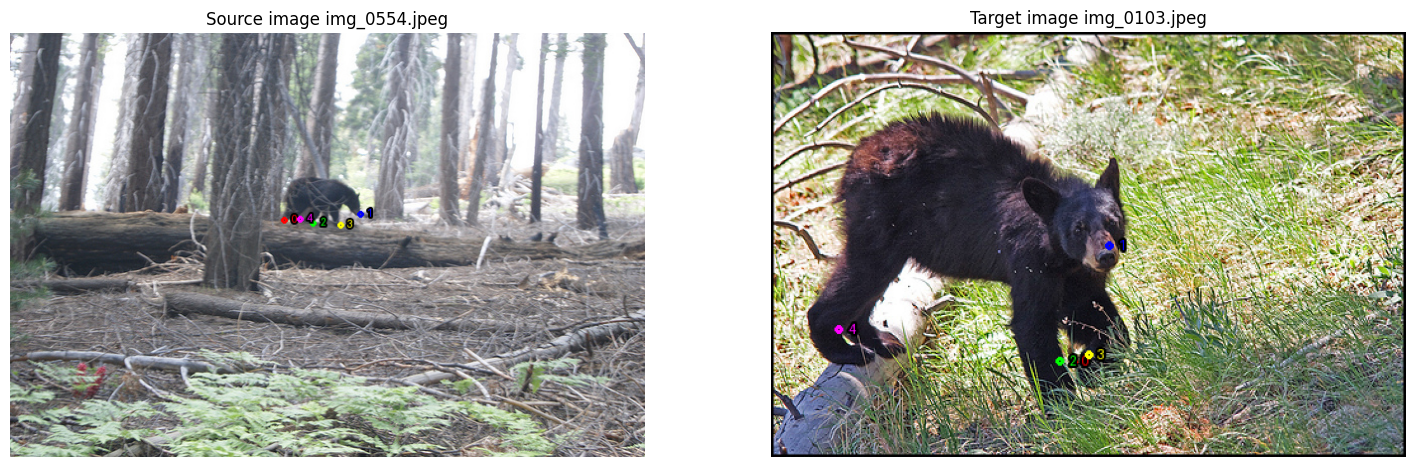

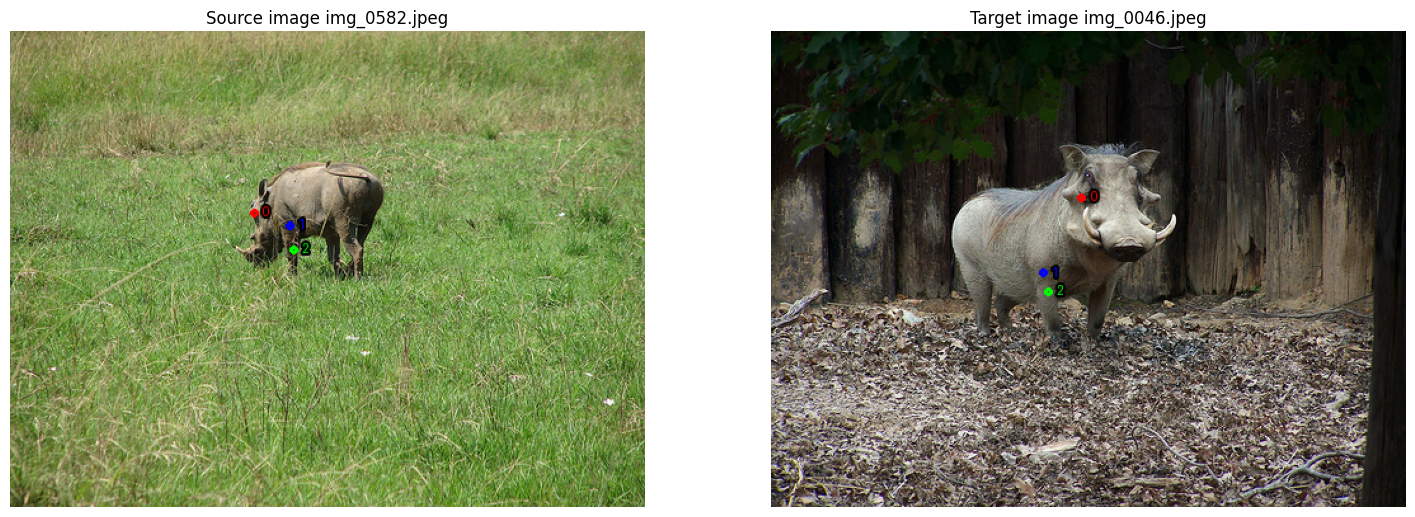

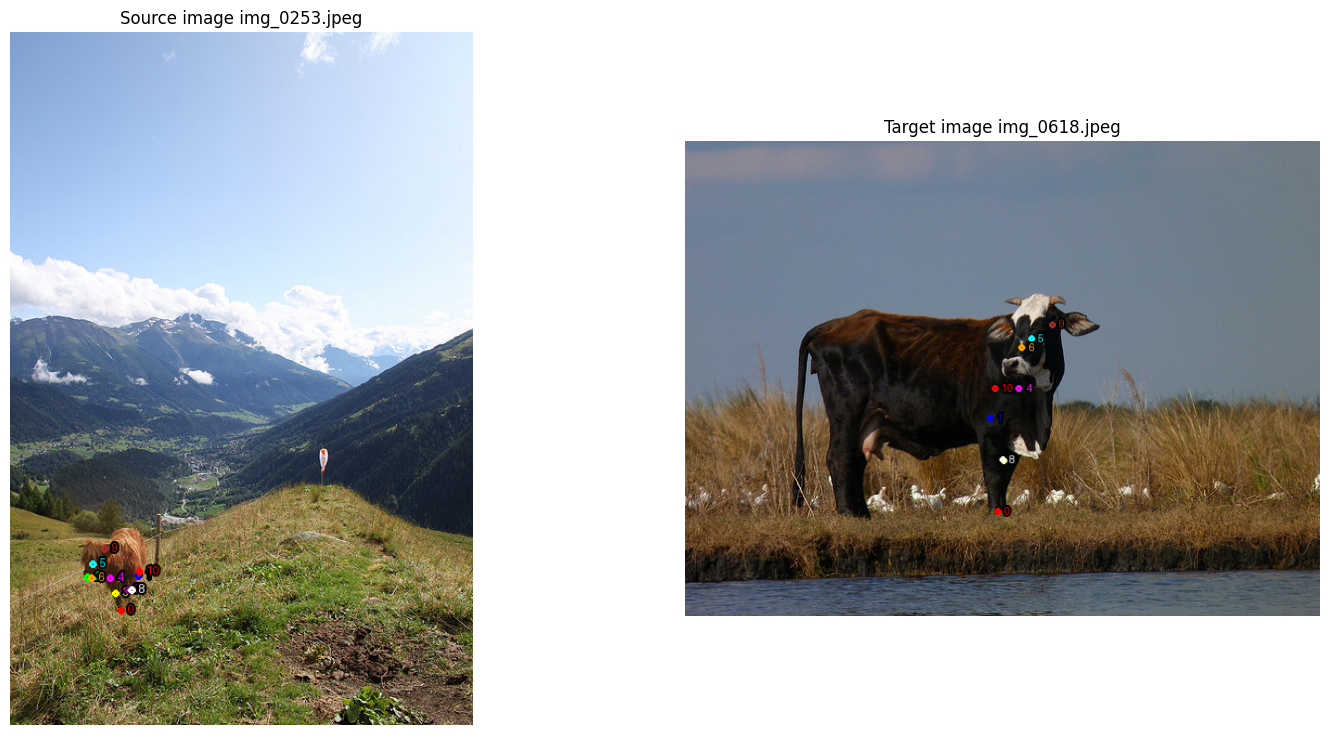

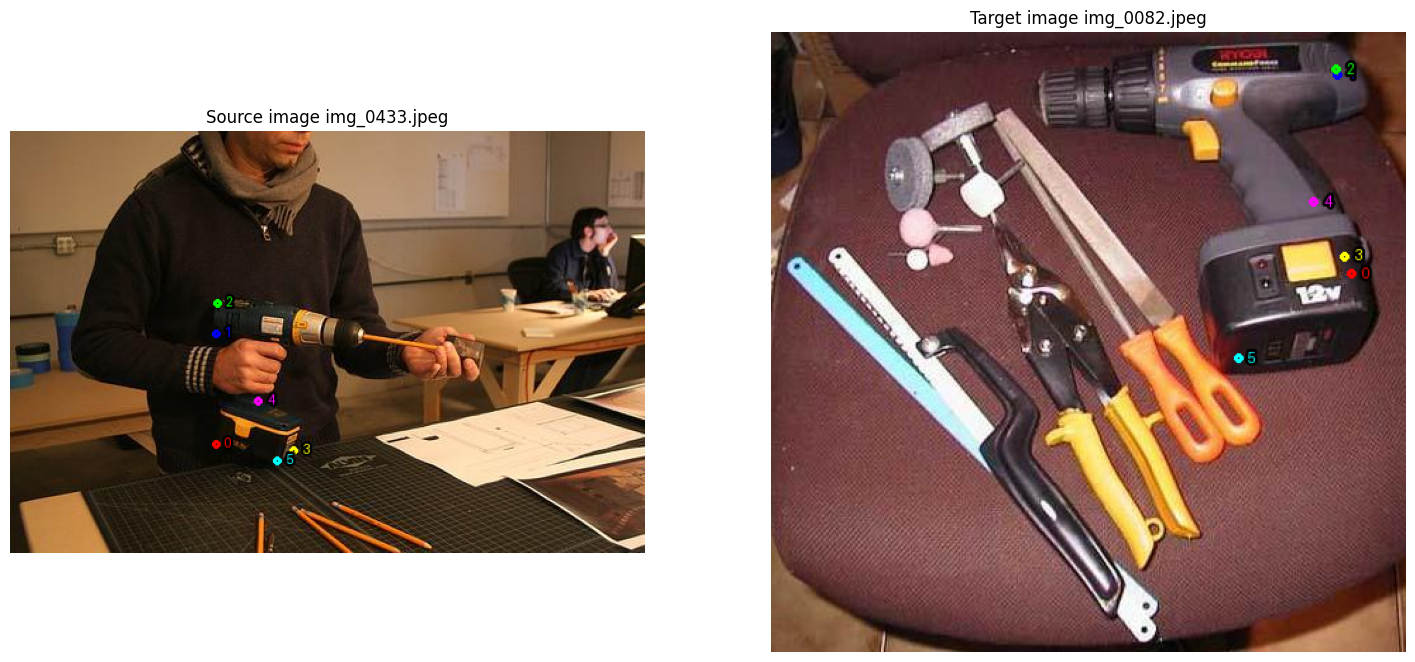

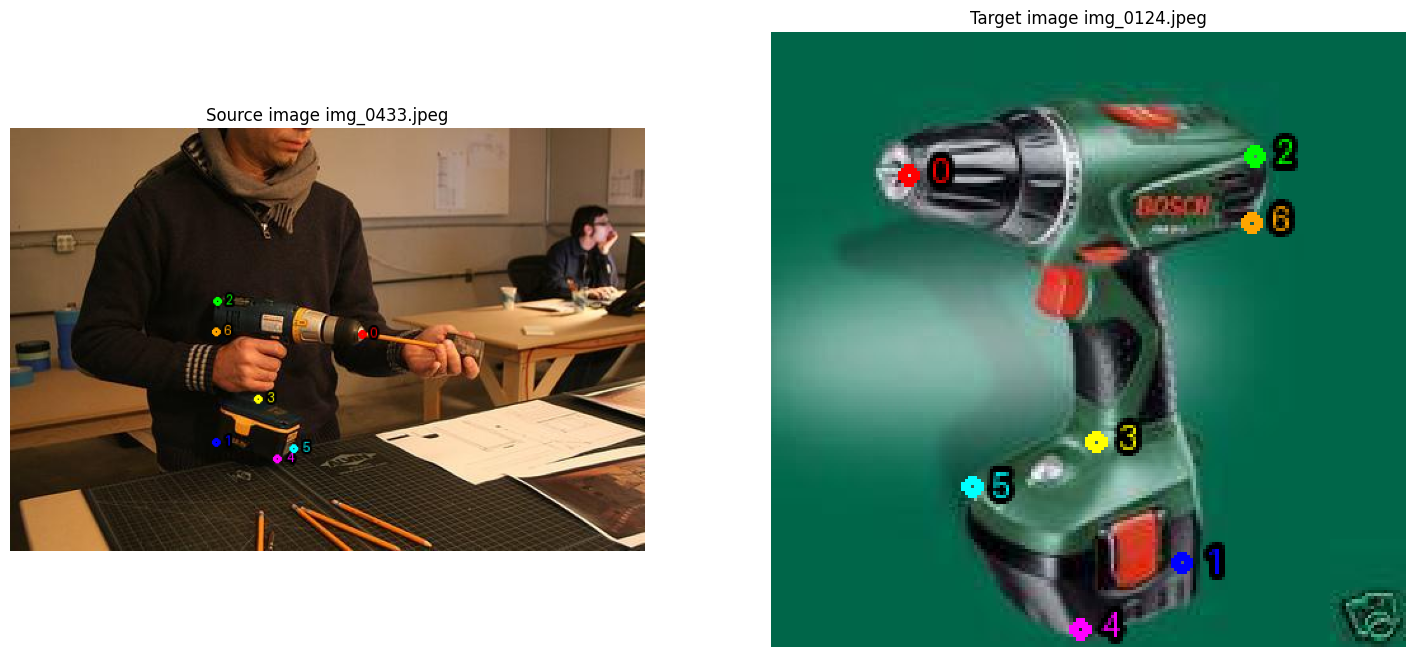

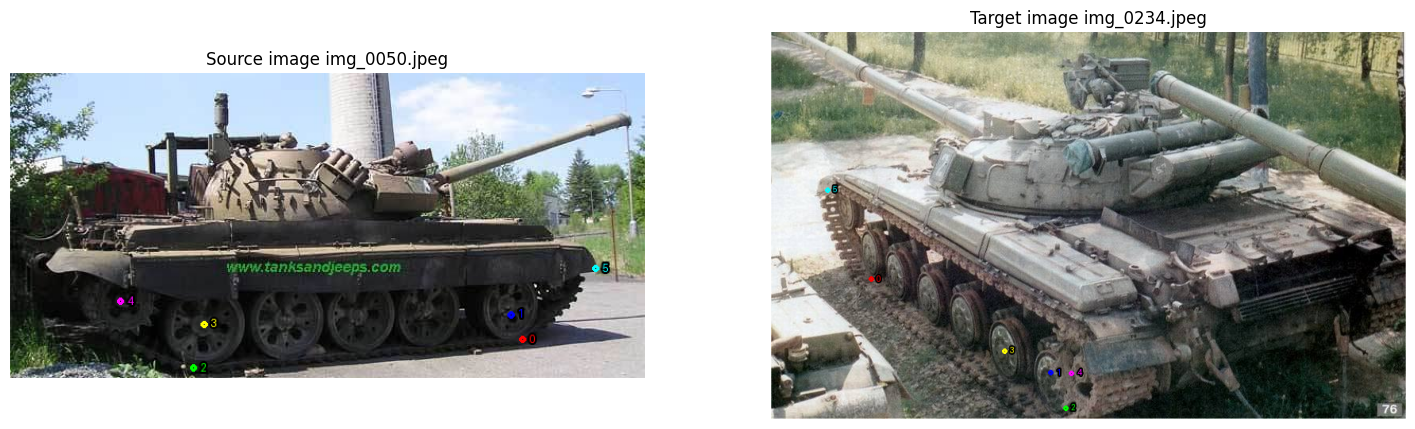

In [52]:
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import json

def show_points(source_path, target_path, queries, submission_csv, radius=3):
    source = Image.open(source_path).convert('RGB')
    target = Image.open(target_path).convert('RGB')
    
    source_draw = ImageDraw.Draw(source)
    target_draw = ImageDraw.Draw(target)

    colors = [
        'red', 'blue', 'lime', 'yellow', 'magenta',
        'cyan', 'orange', 'purple', 'white', 'brown'
    ]

    try:
        font = ImageFont.truetype("arial.ttf", 18)
    except:
        font = ImageFont.load_default()
    
    for i, query in enumerate(queries):
        color = colors[i % len(colors)]

        source_x, source_y = query['xy']
        test_id = query['id']
        prediction = submission_csv.loc[submission_csv['id'].astype(str) == str(test_id), 'prediction'].values[0]
        target_x, target_y = json.loads(prediction)

        # Draw circle on image
        source_draw.ellipse(
            (source_x-radius, source_y-radius, source_x+radius, source_y+radius),
            outline=color,
            width=3
        )
        
        target_draw.ellipse(
            (target_x-radius, target_y-radius, target_x+radius, target_y+radius),
            outline=color,
            width=3
        )

        # Draw query index next to the point
        source_draw.text(
            (source_x + radius + 4, source_y - radius - 4),
            str(i),
            fill=color,
            font=font,
            stroke_width=2,
            stroke_fill='black'
        )

        target_draw.text(
            (target_x + radius + 4, target_y - radius - 4),
            str(i),
            fill=color,
            font=font,
            stroke_width=2,
            stroke_fill='black'
        )
    _, _, source_name = source_path.split('/')
    fig, axes = plt.subplots(1, 2, figsize=(18, 9))
    axes[0].imshow(source)
    axes[0].set_title(f'Source image {source_name}')
    axes[0].axis('off')

    _, _, target_name = target_path.split('/')
    axes[1].imshow(target)
    axes[1].set_title(f'Target image {target_name}')
    axes[1].axis('off')

submission_csv = pd.read_csv("submission.csv")
for idx, row in enumerate(test_pairs):
    source_path = row['source_image']
    target_path = row['target_image']
    queries = row['queries']
    show_points(source_path, target_path, queries, submission_csv) 
    if idx == 5: break
    

